<a href="https://colab.research.google.com/github/abrar-ahmed00/AI/blob/main/ai_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Path: ['2', '0', '5']
Total Cost: 6


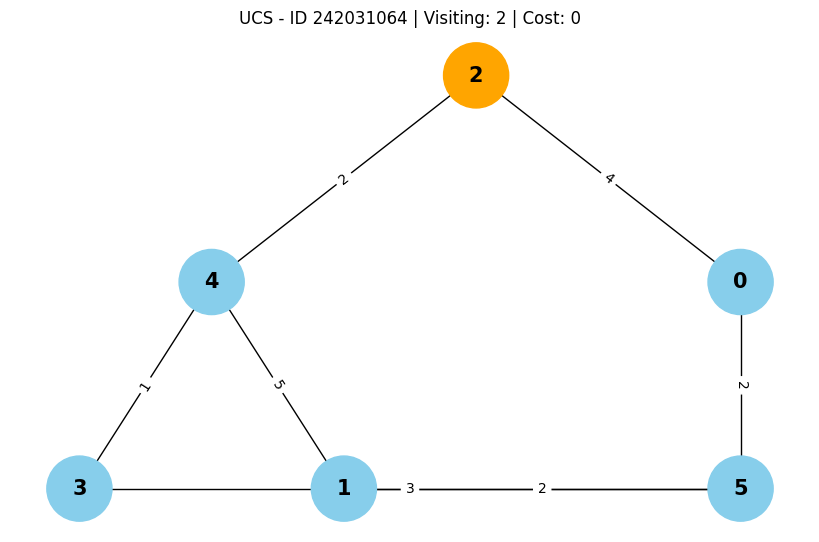

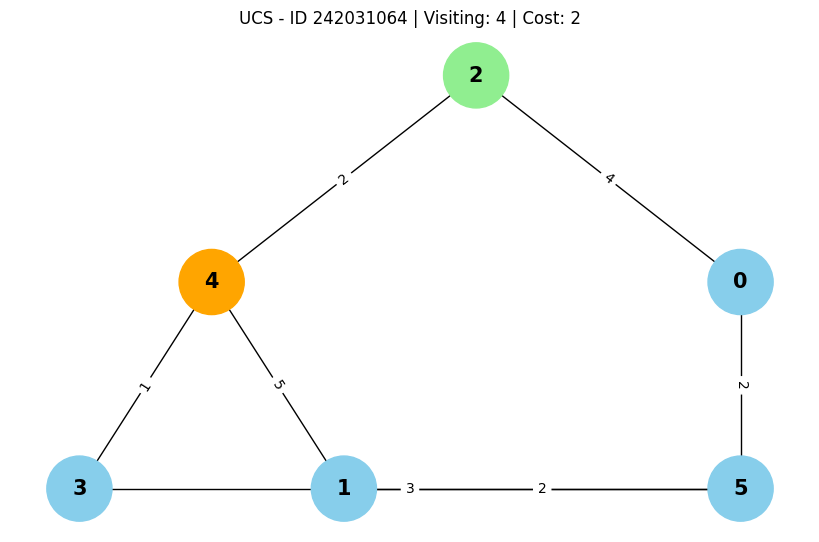

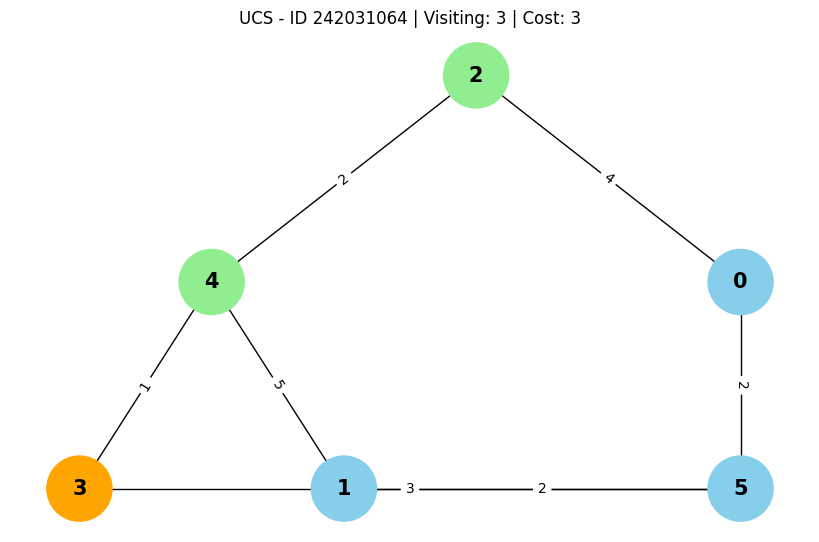

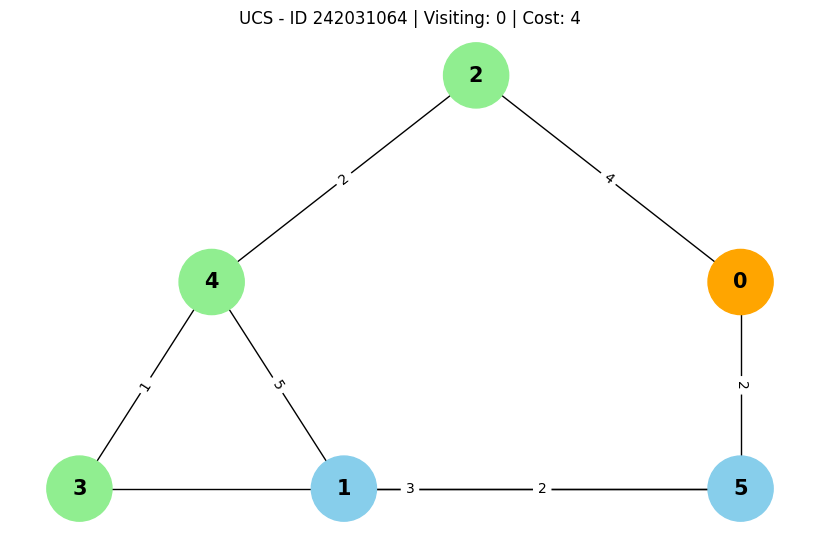

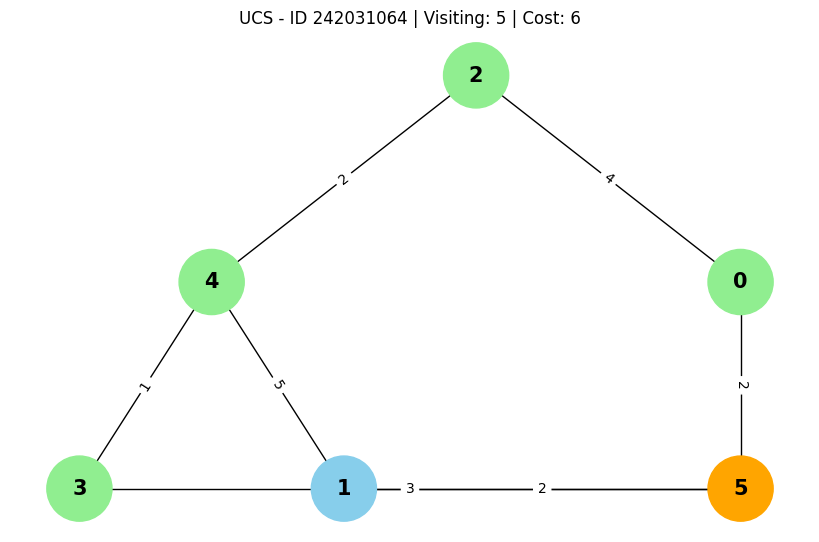

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import heapq

graph = {
    '2': [('4', 2), ('0', 4)],
    '4': [('3', 1), ('1', 5)],
    '0': [('5', 2)],
    '3': [('5', 3)],
    '1': [('5', 2)],
    '5': []
}

def UCS(start, target):

    pq = [(0, start, [start])]
    visited = []
    steps = []

    while pq:

        cost, node, path = heapq.heappop(pq)

        if node in visited:
            continue

        visited.append(node)
        steps.append((node, visited.copy(), cost))

        if node == target:
            print("Path:", path)
            print("Total Cost:", cost)
            break

        for neighbor, weight in graph[node]:

            if neighbor not in visited:
                heapq.heappush(
                    pq,
                    (cost + weight, neighbor, path + [neighbor])
                )

    G = nx.Graph()

    for node, neighbors in graph.items():
        for neighbor, weight in neighbors:
            G.add_edge(node, neighbor, weight=weight)

    pos = {
        '2': (0, 3),
        '4': (-1, 2),
        '0': (1, 2),
        '3': (-1.5, 1),
        '1': (-0.5, 1),
        '5': (1, 1)
    }

    for node, done, cost in steps:

        plt.figure(figsize=(8, 5))

        colors = [
            'orange' if n == node
            else 'lightgreen' if n in done
            else 'skyblue'
            for n in G.nodes()
        ]

        nx.draw(
            G, pos,
            with_labels=True,
            node_color=colors,
            node_size=2200,
            font_size=15,
            font_weight='bold'
        )

        nx.draw_networkx_edge_labels(
            G, pos,
            edge_labels=nx.get_edge_attributes(G, 'weight')
        )

        plt.title(f"UCS - ID 242031064 | Visiting: {node} | Cost: {cost}")
        plt.show()

UCS('2', '5')